# Braun et al. (2026), Fig. 5 and Supp. Fig. 10 — downstream sequences scaffolded by an upstream sequence (WP0.6)

> B: upstream activity (a = 0.5, σ = 1 s, b = 0.3) and the trained downstream response. C: a wider downstream target
> (σ = 2 s) is learned (corr 0.99). D: a narrower one (σ = 0.5 s) less well (0.87). E–G: correlation against
> downstream width, amplitude and offset: narrower-than-upstream targets fail; amplitude and offset do not matter.
> Supp. 10: A untrained (all-ones) readout; B, C lower amplitude / offset; D, E upstream silencing / current injection
> propagate downstream.

**Panels:** B · C · D · E width sweep · F amplitude sweep · G offset sweep · H (added) ‖A‖₂ against the supplement's
scaffolding bound (Suppl. eq. 6) · S10A–E.

**Acceptance (spec WP0.6):** correlation ≥ 0.99 for σ_d ≥ σ_u = 1 s, falling to ≈ 0.8 at σ_d = 0.4 s; insensitive to
amplitude and offset. ‖A‖₂ ≥ the Suppl. §7 bound wherever σ_d < σ_u (T18).

Readout rule: `seqnet.training.readout.braun_downstream` (Methods lines 1264–1275).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seqnet.figures import Figure, style
from seqnet.experiments import wp0
from seqnet.targets import SequenceSpec, sequence_rates
from seqnet.models.rate_rnn import simulate, RNNParams, Perturbation
from seqnet.training.readout import braun_downstream
from seqnet.spectral.braun_map import scaffolding_bound

style()
fig = Figure("wp0", "braun_fig5")
cfg = fig.config(); prm = RNNParams()
n_t = int(round(cfg["t_max"] / prm.dt)) + 1
t = np.arange(n_t) * prm.dt

def upstream(p, perts=(), noise=cfg["upstream_noise"]):
    run = wp0.get(p["amp"], p["width"], p["offset"], cfg["settings"])
    spec = SequenceSpec(amp=p["amp"], width=p["width"], offset=p["offset"])
    sim = simulate(run.W(cfg["realisation"]), spec.h_target(np.array([0.0]))[:, 0], n_t, prm, np.random.default_rng(cfg["seed"]),
                   noise=noise, perturbations=perts)
    return sim["r"].T, run

def down_target(p):
    return sequence_rates(cfg["N_d"], 8.5, p["amp"], p["width"], p["offset"], t)

U, run_u = upstream(cfg["upstream"])
def train(p):
    return braun_downstream(U, down_target(p), cfg["alpha"], cfg["n_iter"])
run_u.meta["settings"]

'dev'

## Panels B–D — upstream activity and downstream responses

In [2]:
res = {k: train(cfg["panels"][k]) for k in ("B", "C", "D")}
fig.save("BCD", t=t, U=U[:, ::4].astype(np.float32), **{f"out_{k}": r["output"] for k, r in res.items()},
         **{f"target_{k}": down_target(cfg["panels"][k]) for k in res}, **{f"corr_{k}": r["corr"] for k, r in res.items()})

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig5/BCD.npz')

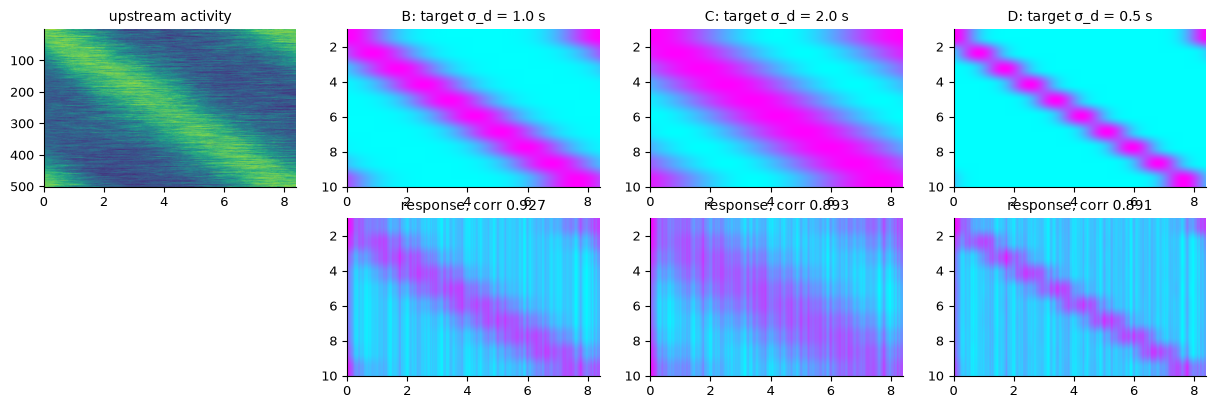

{'B': 0.927, 'C': 0.893, 'D': 0.891} paper: C 0.99, D 0.87


In [3]:
d = fig.load("BCD")
F, axs = plt.subplots(2, 4, figsize=(15, 4.5))
axs[0, 0].imshow(d["U"], aspect="auto", extent=[0, t[-1], 501, 1], vmin=0, vmax=1); axs[0, 0].set_title("upstream activity"); axs[1, 0].axis("off")
for j, k in enumerate(("B", "C", "D"), start=1):
    axs[0, j].imshow(d[f"target_{k}"], aspect="auto", extent=[0, t[-1], 10, 1], cmap="cool"); axs[0, j].set_title(f"{k}: target σ_d = {cfg['panels'][k]['width']} s")
    axs[1, j].imshow(d[f"out_{k}"], aspect="auto", extent=[0, t[-1], 10, 1], cmap="cool"); axs[1, j].set_title(f"response, corr {float(d[f'corr_{k}']):.3f}")
fig.savefig("BCD", F); plt.show()
print({k: round(float(d[f"corr_{k}"]), 3) for k in "BCD"}, "paper: C 0.99, D 0.87")

## Panels E–G — correlation against downstream width, amplitude and offset

In [4]:
base = cfg["upstream"]
sw = {"width": cfg["width_sweep"], "amp": cfg["amp_sweep"], "offset": cfg["offset_sweep"]}
corrs, norms = {}, {}
for key, vals in sw.items():
    cs, ns_ = [], []
    for v in vals:
        p = dict(amp=0.5, width=1.0, offset=0.3); p[key] = v
        r = train(p); cs.append(r["corr"]); ns_.append(np.linalg.norm(r["A"], 2))
    corrs[key], norms[key] = np.array(cs), np.array(ns_)
fig.save("EFG_sweeps", **{f"vals_{k}": np.array(v) for k, v in sw.items()}, **{f"corr_{k}": v for k, v in corrs.items()},
         **{f"norm_{k}": v for k, v in norms.items()})

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig5/EFG_sweeps.npz')

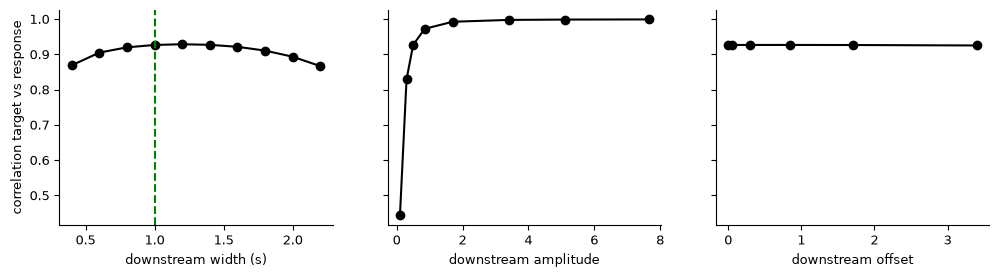

{'width': array([0.869, 0.905, 0.92 , 0.927, 0.929, 0.927, 0.921, 0.911, 0.893,
       0.867]), 'amp': array([0.443, 0.829, 0.927, 0.972, 0.992, 0.998, 0.999, 0.999]), 'offset': array([0.927, 0.927, 0.927, 0.927, 0.927, 0.925])}


In [5]:
d = fig.load("EFG_sweeps")
F, axs = plt.subplots(1, 3, figsize=(12, 2.8), sharey=True)
for ax, k, lab in zip(axs, ["width", "amp", "offset"], ["downstream width (s)", "downstream amplitude", "downstream offset"]):
    ax.plot(d[f"vals_{k}"], d[f"corr_{k}"], "ko-"); ax.set_xlabel(lab)
axs[0].axvline(1.0, color="g", ls="--"); axs[0].set_ylabel("correlation target vs response")
fig.savefig("EFG_sweeps", F); plt.show()
print({k: np.round(d[f"corr_{k}"], 3) for k in ["width", "amp", "offset"]})

## Panel H (added) — readout norm against the scaffolding bound (Braun Suppl. eq. 6; spec T18)

‖A‖₂ of the trained readout against q √(N_d/N_u) (a_d σ_d)/(a_u σ_u) exp[(q m ω_u)²(σ_u² − σ_d²)/2] with q = 1, for
m = 1, 2, 3. The bound applies to an exact Gaussian upstream sequence; the realised upstream activity is the trained
network's.

In [6]:
d = fig.load("EFG_sweeps"); w_u = 2 * np.pi / 8.5
sd = d["vals_width"]
B = np.stack([scaffolding_bound(m, 1, cfg["N_d"], 501, 0.5, 0.5, sd, 1.0, w_u) for m in (1, 2, 3)])
fig.save("H_bound", sd=sd, norm=d["norm_width"], bound=B)

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig5/H_bound.npz')

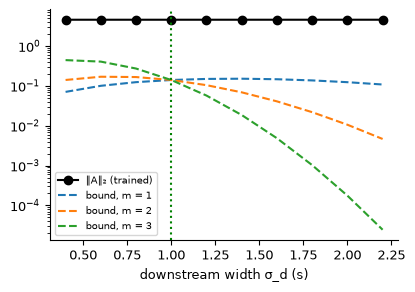

In [7]:
d = fig.load("H_bound")
F, ax = plt.subplots(figsize=(4.5, 3))
ax.semilogy(d["sd"], d["norm"], "ko-", label="‖A‖₂ (trained)")
for m, b in zip((1, 2, 3), d["bound"]): ax.semilogy(d["sd"], b, "--", label=f"bound, m = {m}")
ax.axvline(1.0, color="g", ls=":"); ax.set_xlabel("downstream width σ_d (s)"); ax.legend(fontsize=7)
fig.savefig("H_bound", F); plt.show()

## Panel I (added) — width sweep with a noise-free upstream run ([VERIFY])

The Methods run the upstream network with noise gain 0.5. A diagnostic showed that the 1000-iteration readout then
plateaus near 0.93 (least squares reaches 1.0; 20 000 iterations reach 0.99), whereas a noise-free upstream run gives
0.99 within 1000 iterations, the paper's value.

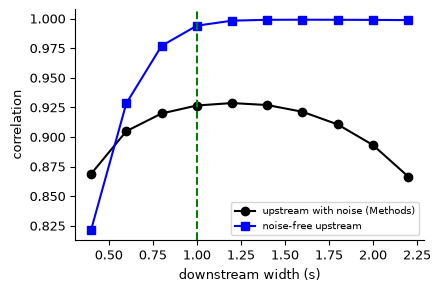

[0.822 0.929 0.977 0.994 0.998 0.999 0.999 0.999 0.999 0.999]


In [8]:
U0, _ = upstream(cfg["upstream"], noise=False)
cs = [braun_downstream(U0, down_target(dict(amp=0.5, width=v, offset=0.3)), cfg["alpha"], cfg["n_iter"])["corr"] for v in cfg["width_sweep"]]
fig.save("I_noise_free", width=np.array(cfg["width_sweep"]), corr=np.array(cs), corr_noisy=fig.load("EFG_sweeps")["corr_width"])
d = fig.load("I_noise_free")
F, ax = plt.subplots(figsize=(4.5, 3)); ax.plot(d["width"], d["corr_noisy"], "ko-", label="upstream with noise (Methods)"); ax.plot(d["width"], d["corr"], "bs-", label="noise-free upstream")
ax.axvline(1.0, color="g", ls="--"); ax.set_xlabel("downstream width (s)"); ax.set_ylabel("correlation"); ax.legend(fontsize=7)
fig.savefig("I_noise_free", F); plt.show(); print(np.round(d["corr"], 3))

## Supp. 10 A–C — untrained readout, lower downstream amplitude, lower downstream offset

In [9]:
A1 = np.ones((cfg["N_d"], 501)); outA = A1 @ U
rB, rC = train(cfg["supp10"]["B"]), train(cfg["supp10"]["C"])
fig.save("S10_ABC", outA=outA, outB=rB["output"], outC=rC["output"], corrB=rB["corr"], corrC=rC["corr"],
         tB=down_target(cfg["supp10"]["B"]), tC=down_target(cfg["supp10"]["C"]))

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig5/S10_ABC.npz')

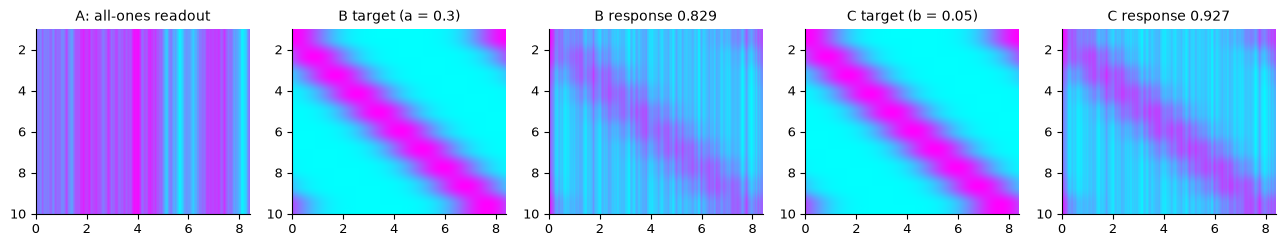

In [10]:
d = fig.load("S10_ABC")
F, axs = plt.subplots(1, 5, figsize=(16, 2.4))
for ax, k, title in zip(axs, ["outA", "tB", "outB", "tC", "outC"], ["A: all-ones readout", "B target (a = 0.3)", f"B response {float(d['corrB']):.3f}", "C target (b = 0.05)", f"C response {float(d['corrC']):.3f}"]):
    ax.imshow(d[k], aspect="auto", extent=[0, t[-1], 10, 1], cmap="cool"); ax.set_title(title)
fig.savefig("S10_ABC", F); plt.show()

## Supp. 10 D–E — perturbing the upstream network (silencing / current I = 3, 20% of neurons) after training A

In [11]:
pu = cfg["upstream_perturb"]; pp = cfg["perturb"]
U2, _ = upstream(pu)
tgt = down_target(cfg["supp10"]["DE"]); rt = braun_downstream(U2, tgt, cfg["alpha"], cfg["n_iter"])
ens = np.arange(pp["first_neuron"], pp["first_neuron"] + int(pp["fraction"] * 501))
s0, s1 = [int(round(x / prm.dt)) for x in pp["window_s"]]
Us, _ = upstream(pu, [Perturbation("silence", ens, s0, s1)])
Uc, _ = upstream(pu, [Perturbation("current", ens, s0, s1, pp["current"])])
outs, outc = rt["A"] @ Us, rt["A"] @ Uc
corr = lambda a, b: float(np.corrcoef(a.ravel(), b.ravel())[0, 1])
fig.save("S10_DE", Us=Us[:, ::4].astype(np.float32), Uc=Uc[:, ::4].astype(np.float32), outs=outs, outc=outc, corr_s=corr(outs, tgt), corr_c=corr(outc, tgt), win=np.array(pp["window_s"]), ens=ens)

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig5/S10_DE.npz')

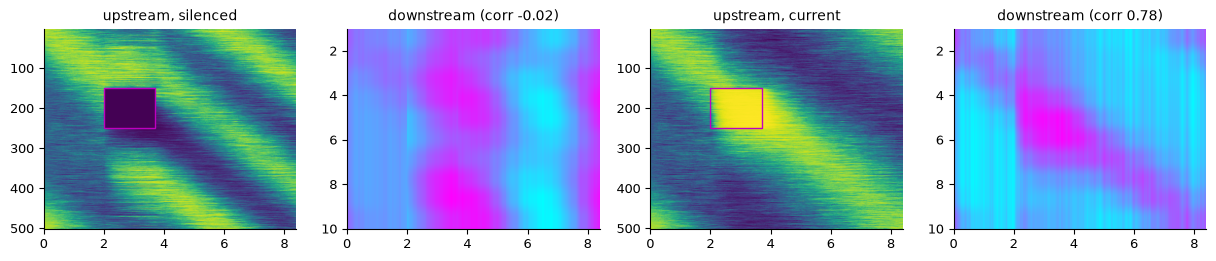

In [12]:
d = fig.load("S10_DE")
F, axs = plt.subplots(1, 4, figsize=(15, 2.6))
for ax, k, title in zip(axs, ["Us", "outs", "Uc", "outc"], ["upstream, silenced", f"downstream (corr {float(d['corr_s']):.2f})", "upstream, current", f"downstream (corr {float(d['corr_c']):.2f})"]):
    n = d[k].shape[0]; ax.imshow(d[k], aspect="auto", extent=[0, t[-1], n, 1], cmap="viridis" if n > 10 else "cool"); ax.set_title(title)
    if n > 10: ax.add_patch(plt.Rectangle((d["win"][0], d["ens"][0]), d["win"][1] - d["win"][0], len(d["ens"]), fill=False, ec="m"))
fig.savefig("S10_DE", F); plt.show()

## Acceptance

In [13]:
e = fig.load("EFG_sweeps"); h = fig.load("H_bound")
wv, wc = e["vals_width"], e["corr_width"]
narrow = wv < 1.0
fig.checks([
    {"item": "wide targets learned", "criterion": "corr >= 0.99 for sigma_d >= 1 s", "value": wc[wv >= 1.0], "passed": bool(np.all(wc[wv >= 1.0] >= 0.99))},
    {"item": "narrow target sigma_d = 0.4 s", "criterion": "corr about 0.8 (|x - 0.8| < 0.1)", "value": float(wc[0]), "passed": bool(abs(wc[0] - 0.8) < 0.1)},
    {"item": "insensitive to amplitude", "criterion": "all corr > 0.95", "value": e["corr_amp"], "passed": bool(e["corr_amp"].min() > 0.95)},
    {"item": "insensitive to offset", "criterion": "all corr > 0.95", "value": e["corr_offset"], "passed": bool(e["corr_offset"].min() > 0.95)},
    {"item": "wide targets learned with a noise-free upstream run ([VERIFY] alternative)", "criterion": "corr >= 0.99 for sigma_d >= 1 s",
     "value": fig.load("I_noise_free")["corr"][wv >= 1.0], "passed": bool(np.all(fig.load("I_noise_free")["corr"][wv >= 1.0] >= 0.99))},
    {"item": "T18: |A|_2 >= scaffolding bound where sigma_d < sigma_u", "criterion": "for m = 1 (the bound that applies to every retained mode)",
     "value": {"norm": h["norm"][narrow], "bound_m1": h["bound"][0][narrow]}, "passed": bool(np.all(h["norm"][narrow] >= h["bound"][0][narrow]))},
])

[FAIL] wide targets learned: [0.92666094 0.92872634 0.92704272 0.92135905 0.91066334 0.89325572
 0.86664504]
[PASS] narrow target sigma_d = 0.4 s: 0.8689225385922609
[FAIL] insensitive to amplitude: [0.44330239 0.82897344 0.92666094 0.97236353 0.99246403 0.99768352
 0.99865813 0.99909169]
[FAIL] insensitive to offset: [0.92658367 0.9265992  0.92666094 0.9267036  0.92651748 0.92523021]
[PASS] wide targets learned with a noise-free upstream run ([VERIFY] alternative): [0.99407387 0.99833412 0.99906491 0.99913114 0.99908224 0.99897735
 0.99880023]
[PASS] T18: |A|_2 >= scaffolding bound where sigma_d < sigma_u: {'norm': array([4.60115761, 4.60125614, 4.60152289]), 'bound_m1': array([0.07109009, 0.10096477, 0.1247056 ])}


WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig5/acceptance.json')